# 01 · Validating the conditional-information estimator on known worlds

**Question.** Does the held-out log-score contrast between a joint model `q(D | V, C)` and a matched context model `q(D | C)` recover a known conditional mutual information `I(D; V | C)`, and under which conditions does it fail?

**Estimand vs estimator.** The scientific target is `E2 = I(D; V | hour, T)` in nats. The observable is

$$\widehat\Delta_{LS} = \frac1N\sum_i \big[\log q_{VC}(d_i\mid v_i,c_i) - \log q_C(d_i\mid c_i)\big]$$

on rows never used to fit either model. For fixed fitted models its expectation decomposes exactly as

$$\mathbb E\,\widehat\Delta_{LS} = I(D;V\mid C) \;-\; \mathbb E\,\mathrm{KL}\big(p(\cdot\mid v,c)\,\|\,q_{VC}\big) \;+\; \mathbb E\,\mathrm{KL}\big(p(\cdot\mid c)\,\|\,q_C\big).$$

A poor context model *inflates* the contrast; a poor or over-confident joint model *deflates* it. The contrast is the CMI only when both models are right, so each failure mode below is a concrete instance of one KL term.

**Implementation under test** (`scoring.contrast`). Inputs pass `policy.select_sci` (identical context columns; the joint model adds visual columns). Default family: Gaussian, ridge mean on standardised inputs with the penalty chosen by day-grouped inner CV, SD from grouped inner out-of-fold residuals. Variants: `var='hetero'` (log-link regression of squared residuals) and `resid='kde'` (location-scale model with a KDE density of standardised residuals). Outer folds hold whole days (5, interleaved). Uncertainty: percentile bootstrap over days, **conditional on the fitted models**.

**Tolerances**, declared after a 60-replicate pilot of one positive case (truth 0.154 nats, 60 days: bias +0.003, CI coverage 0.85) and before the first full run:

- T1 null, 60 days: |mean estimate| ≤ 0.01 nats and false-positive rate P(lower 95 % bound > 0) ≤ 0.10;
- T2 positive control: |bias| ≤ 0.01 nats at truth 0.05 (60 days) and estimate-vs-truth slope in [0.9, 1.1];
- T3 block-bootstrap 95 % CI coverage ≥ 0.85 at 60 days and ≥ 0.90 at 180 days;
- T4 every failure mode below must be visible (a false signal or false null), and its declared fix must bring the estimate within 0.02 nats of the truth.

The first full run failed T3 and three T4 items; §11 records those outcomes and the revisions made in response. This is the second run.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from visual_hygrometry import data, policy, scoring, splits, synthetic
from visual_hygrometry.synthetic import Node

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (8, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 4)

HOUR = ['hour_s1', 'hour_c1', 'hour_s2', 'hour_c2']
E2 = HOUR + ['temp_cond_c']
cyc = lambda a, b: (lambda h: a + b * np.cos(2 * np.pi * (h - 15) / 24))
base = {'temp_cond_c': Node(sd=3, mean=cyc(20, 5), day=.7, ar=.95),
        'dres': Node(sd=2, day=.5, ar=.9),
        'd_ref_k': Node({'temp_cond_c': .4, 'dres': 1}, mean=cyc(-1, 2)),
        'vis_moist': Node({'dres': .162}, 1.0, day=.3, ar=.5),
        'vis_temp': Node({'temp_cond_c': 1}, 1.5),
        'vis_sun': Node(sd=.05, mean=lambda h: np.sin(np.pi * (h - 6) / 12))}


def frame(spec, n_days, seed, shared=False):
    df = synthetic.simulate(spec, n_days, seed=seed)
    return pd.concat([df, data.fourier(df.hour, 24, 2, 'hour')], axis=1).assign(hour_local=df.hour, ref_sensor_id='ref', cond_sensor_id='ref' if shared else 'cond')


def estimate(df, level, ctx, vis, shared=False, **kw):
    Xc, Xvc, y, _ = policy.select_sci(df, level, ctx, vis, allow_shared_sensor=shared)
    sp = splits.kfold(splits.assign_folds(df.day.to_numpy(), 5))
    return scoring.contrast(Xc.to_numpy(), Xvc.to_numpy(), y.to_numpy(), sp, df.day.to_numpy(), **kw)


def row(r, truth, **extra):
    lo, hi = r.ci()
    return dict(**extra, truth=truth, est=r.mean, lo=lo, hi=hi)


def replicate(spec, level, ctx, vis, truth, seeds=range(10), n_days=60, shared=False, **kw):
    """Mean and spread of the estimate over independent samples of the same world."""
    est = np.array([estimate(frame(spec, n_days, s, shared), level, ctx, vis, shared, **kw).mean for s in seeds])
    return dict(truth=truth, mean_est=est.mean(), sd_est=est.std(ddof=1), se_mean=est.std(ddof=1) / np.sqrt(len(est)), bias=est.mean() - truth)

## 1 · Dependency intervals: what purging costs

Rows that share look-back history or label windows are not independent. `splits.purge` drops training rows whose interval `[t − look-back, t + 15 min]` comes within a 1 h embargo of any evaluation interval; `overlaps_after` re-counts overlaps by brute force after purging.

In [2]:
df = frame(base, 60, seed=0)
t = pd.Series(pd.Timestamp('2025-06-01', tz='UTC') + pd.to_timedelta(df.day, unit='D') + pd.to_timedelta(df.hour, unit='h'))
rows = []
for look in ['0h', '6h', '24h']:
    start, end = t - pd.Timedelta(look), t + pd.Timedelta('15min')
    for unit, how in [('D', 'contiguous'), ('D', 'interleaved'), ('W', 'interleaved')]:
        fold = splits.assign_folds(splits.blocks(t, unit), 5, how)
        sp = splits.kfold(fold, start, end, embargo='1h')
        s, e, emb = data.ns(start), data.ns(end), pd.Timedelta('1h').value
        left = max(((s[tr][:, None] <= e[te][None] + emb) & (e[tr][:, None] >= s[te][None] - emb)).sum() for tr, te in sp)
        rows.append(dict(lookback=look, block=unit, assign=how, train_rows_purged=np.mean([1 - tr.sum() / (fold != f).sum() for f, (tr, _) in enumerate(sp)]), overlaps_after=left))
pd.DataFrame(rows)

,lookback,block,assign,train_rows_purged,overlaps_after
0,0h,D,contiguous,0.0000,0
1,0h,D,interleaved,0.0000,0
2,0h,W,interleaved,0.0000,0
3,6h,D,contiguous,0.0000,0
4,6h,D,interleaved,0.0000,0
5,6h,W,interleaved,0.0000,0
6,24h,D,contiguous,0.0333,0
7,24h,D,interleaved,0.4917,0
8,24h,W,interleaved,0.0757,0


Daylight-only sampling (06–18 h) leaves a 12 h night gap, so 6 h histories never cross days and nothing is purged. A 24 h temperature history changes that: interleaved day folds lose about half of the training rows (both neighbours of every test day), contiguous day folds ~3 % and interleaved week folds ~8 %. The look-back ablation planned for Exp 5 therefore needs week blocks or contiguous folds; with 24 h imagery (night frames) even 6 h histories would cross days.

## 2 · Null and positive controls on one sample

Three visual features under E2 (context = hour basis + T): a sun-elevation cue (function of hour only, truth 0), a visual thermometer (truth 0 once T is conditioned), and the moisture cue (truth 0.05). One 60-day sample, so the positive estimate scatters by ~0.02 nats (§10).

In [3]:
df = frame(base, 60, seed=0)
pd.DataFrame([row(estimate(df, 'e2', E2, [v]), synthetic.cmi(base, 'd_ref_k', v, 'temp_cond_c'), vis=v) for v in ['vis_sun', 'vis_temp', 'vis_moist']]).set_index('vis')

,truth,est,lo,hi
vis,,,,
vis_sun,0.0000,7.6471e-05,-0.0006,0.0007
vis_temp,0.0000,-1.7478e-04,-0.0017,0.0012
vis_moist,0.0499,1.3036e-02,-0.0074,0.0306


## 3 · Positive-control sweep

Vary the moisture-cue strength γ so the true E2 spans 0–0.54 nats; one 60-day sample per point.

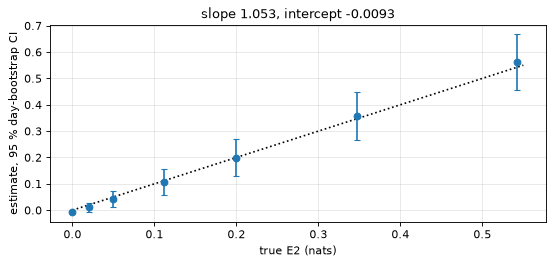

,gamma,truth,est,lo,hi
0,0.000,-2.2204e-16,-0.0057,-0.0109,-0.0013
1,0.100,1.9610e-02,0.0108,-0.0073,0.0290
2,0.162,4.9912e-02,0.0418,0.0112,0.0737
3,0.250,1.1157e-01,0.1062,0.0580,0.1571
4,0.350,1.9939e-01,0.1998,0.1312,0.2698
5,0.500,3.4657e-01,0.3567,0.2667,0.4474
6,0.700,5.4259e-01,0.5624,0.4561,0.6691


In [4]:
sweep = []
for g in [0, .1, .162, .25, .35, .5, .7]:
    spec = base | {'vis_moist': Node({'dres': g}, 1.0, day=.3, ar=.5)}
    sweep.append(row(estimate(frame(spec, 60, seed=10), 'e2', E2, ['vis_moist']), synthetic.cmi(spec, 'd_ref_k', 'vis_moist', 'temp_cond_c'), gamma=g))
sweep = pd.DataFrame(sweep)
slope, icpt = np.polyfit(sweep.truth, sweep.est, 1)
plt.errorbar(sweep.truth, sweep.est, yerr=[sweep.est - sweep.lo, sweep.hi - sweep.est], fmt='o', capsize=3)
plt.plot([0, .55], [0, .55], 'k:'); plt.xlabel('true E2 (nats)'); plt.ylabel('estimate, 95 % day-bootstrap CI'); plt.title(f'slope {slope:.3f}, intercept {icpt:+.4f}')
plt.show()
sweep

## 4 · E1 vs E2: thermometry and synergy

`vis_temp` sees temperature only. `vis_vapor` sees the dew point `Td = T − D` (absolute moisture, e.g. a vapour-dependent attenuation). Without T, a dew-point cue says little about `D`; with T, it pins `D` down. Conditioning can remove information (thermometer) or create it (synergy), so E1 and E2 must each be estimated. Ten 60-day samples per row.

In [5]:
vap = {k: base[k] for k in ['temp_cond_c', 'dres', 'd_ref_k']} | {'vapor': Node({'temp_cond_c': 1, 'd_ref_k': -1}), 'vis_vapor': Node({'vapor': 1}, 1.0)}
rows = []
for spec, v in [(base, 'vis_temp'), (vap, 'vis_vapor')]:
    rows.append(dict(vis=v, level='E1') | replicate(spec, 'e1', HOUR, [v], synthetic.cmi(spec, 'd_ref_k', v)))
    rows.append(dict(vis=v, level='E2') | replicate(spec, 'e2', E2, [v], synthetic.cmi(spec, 'd_ref_k', v, 'temp_cond_c')))
pd.DataFrame(rows).set_index(['vis', 'level'])

truth    mean_est  sd_est  se_mean        bias
vis       level                                                 
vis_temp  E1     0.1190  1.1029e-01  0.0430   0.0136 -8.6919e-03
          E2     0.0000  7.1469e-08  0.0009   0.0003  7.1469e-08
vis_vapor E1     0.0393  3.9483e-02  0.0292   0.0092  2.1632e-04
          E2     0.8047  8.2179e-01  0.0746   0.0236  1.7073e-02

## 5 · Failure mode A — under-fitted context (KL_C > 0)

The context model gets local hour as a *linear* term instead of the Fourier basis. The diurnal cycle of `D` is curved, and the sun-elevation cue (a smooth function of hour, truth 0) lets the joint model repair the context model's deficit. Ten 60-day samples, plus the residual diagnostic on one of them.

In [6]:
pd.DataFrame({'linear hour': replicate(base, 'e2', ['hour_local', 'temp_cond_c'], ['vis_sun'], 0.0),
              'Fourier hour (fix)': replicate(base, 'e2', E2, ['vis_sun'], 0.0)}).T

,truth,mean_est,sd_est,se_mean,bias
linear hour,0.0,0.0168,0.0080,0.0025,0.0168
Fourier hour (fix),0.0,-0.0002,0.0006,0.0002,-0.0002


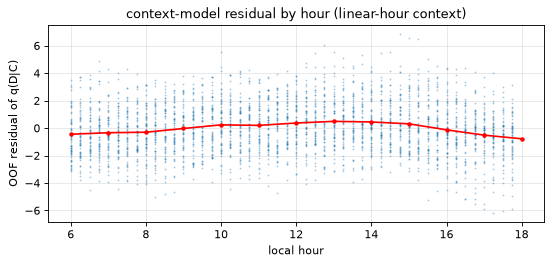

In [7]:
df = frame(base, 60, seed=5)
rA = estimate(df, 'e2', ['hour_local', 'temp_cond_c'], ['vis_sun'])
res = df.d_ref_k - rA.pred_c[0]
plt.plot(df.hour, res, '.', ms=1.5, alpha=.3); plt.plot(*zip(*res.groupby(df.hour.round()).mean().items()), 'r-o', ms=3)
plt.xlabel('local hour'); plt.ylabel('OOF residual of q(D|C)'); plt.title('context-model residual by hour (linear-hour context)'); plt.show()

The spurious contrast is small here (the diurnal curvature is mild) but systematic across samples. The residual-by-hour plot is the diagnostic available on real data: structure in context residuals against context variables means `q(D | C)` is not competitive yet, and a positive contrast cannot be read as visual information.

## 6 · Failure mode B — too many visual dimensions for the effective sample size (KL_VC > 0)

30 days (1440 rows) and 200 pure-noise visual features beside the real cue; the truth stays 0.0499 because the noise features carry nothing. Variants of the matched pair: OLS with in-sample SD, OLS with out-of-fold SD, ridge tuned by row-wise leave-one-out (sklearn `RidgeCV`, which treats autocorrelated rows as independent), ridge tuned by day-grouped CV (default), and the default with the real cue alone. Five samples each.

In [8]:
nuis = {f'vis_n{j:03d}': Node(sd=1) for j in range(200)}
spec6, vis6 = base | nuis, ['vis_moist'] + list(nuis)
truth6 = synthetic.cmi(spec6, 'd_ref_k', vis6, 'temp_cond_c')
ols = lambda: make_pipeline(StandardScaler(), LinearRegression())
loo = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=scoring.ALPHAS))
variants = {'OLS, in-sample SD': (vis6, dict(model=ols, var='insample')), 'OLS, OOF SD': (vis6, dict(model=ols)), 'ridge, row-LOO tuned': (vis6, dict(model=loo)),
            'ridge, day-grouped tuned': (vis6, {}), 'cue only (1 dimension)': (['vis_moist'], {})}
B, calib, df6 = {}, [], frame(spec6, 30, 0)
y = df6.d_ref_k.to_numpy()
for k, (vis, kw) in variants.items():
    B[k] = replicate(spec6, 'e2', E2, vis, truth6, seeds=range(5), n_days=30, **kw)
    r = estimate(df6, 'e2', E2, vis, **kw)
    calib.append(dict(variant=k, cover90_joint=scoring.coverage(y, *r.pred_vc[:2]), cover90_ctx=scoring.coverage(y, *r.pred_c[:2]), pit=scoring.pit(y, *r.pred_vc[:2])))
pd.DataFrame(B).T.join(pd.DataFrame(calib).set_index('variant')[['cover90_joint', 'cover90_ctx']])

,truth,mean_est,sd_est,se_mean,bias,cover90_joint,cover90_ctx
"OLS, in-sample SD",0.0499,-0.1196,0.0347,0.0155,-0.1695,0.7861,0.8861
"OLS, OOF SD",0.0499,-0.0412,0.0367,0.0164,-0.0911,0.8944,0.9118
"ridge, row-LOO tuned",0.0499,-0.0278,0.0367,0.0164,-0.0778,0.8986,0.9111
"ridge, day-grouped tuned",0.0499,-0.0262,0.0396,0.0177,-0.0762,0.8972,0.9090
cue only (1 dimension),0.0499,0.0423,0.0280,0.0125,-0.0077,0.8944,0.9090


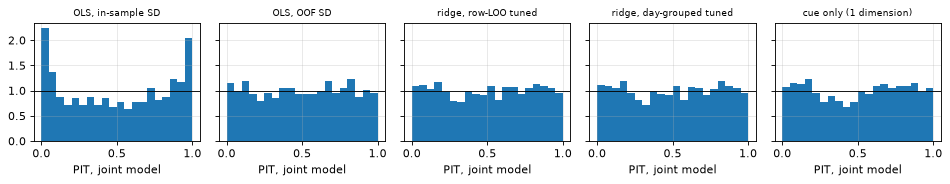

In [9]:
fig, ax = plt.subplots(1, 5, figsize=(12, 2.4), sharey=True)
for a, c in zip(ax, calib):
    a.hist(c['pit'], bins=20, range=(0, 1), density=True); a.axhline(1, c='k', lw=.8); a.set_title(c['variant'], fontsize=8); a.set_xlabel('PIT, joint model')
plt.tight_layout(); plt.show()

Out-of-fold variance repairs calibration (coverage ≈ 0.9, flat PIT) but not the estimation cost: with 200 dimensions and ~30 independent days every estimator loses more to fitting noise than the 0.05-nat signal is worth, so the contrast becomes a false null. Grouped and row-wise penalty tuning give nearly the same answer here; grouped tuning is kept because it follows the blocked-CV rule, not because it fixes this case. The fix is a **dimension budget**: compact, pre-specified visual features (or representations fitted on non-evaluation data) whose count is small relative to the number of independent days.

## 7 · Failure mode C — information in the variance, not the mean

Real humidity regimes differ in spread: near saturation `D` is pinned close to 0, in dry air it wanders. A day-level regime sets the SD of the moisture residual (0.7 K vs 2.5 K) without changing its mean; a visual cue reveals the regime (misclassification ≈ Φ(−5)). The truth is the entropy difference of a Gaussian scale mixture (quadrature). The decomposition predicts the Gaussian log-link variant exactly: its context model is the best Gaussian (variance = mixture variance), whose KL from the mixture adds to the truth.

In [10]:
rng = np.random.default_rng(8)
df8 = frame(base, 120, seed=8)
regime = rng.integers(0, 2, df8.day.max() + 1)[df8.day]
df8['d_ref_k'] = df8.d_ref_k - df8.dres + np.where(regime == 1, 0.7, 2.5) * df8.dres / 2
df8['vis_regime'] = regime + rng.normal(0, .1, len(df8))
x = np.linspace(-20, 20, 40001)
p = .5 * norm.pdf(x, 0, .7) + .5 * norm.pdf(x, 0, 2.5)
h_mix = -np.trapezoid(p * np.log(p), x)
truth8 = h_mix - np.mean([.5 * np.log(2 * np.pi * np.e * s ** 2) for s in (.7, 2.5)])
kl_c = .5 * np.log(2 * np.pi * np.e * np.mean([.49, 6.25])) - h_mix
C = {'Gaussian, homoscedastic': dict(), 'Gaussian, log-link variance': dict(var='hetero'), 'location-scale + KDE residual': dict(var='hetero', resid='kde')}
print(f'truth {truth8:.4f} nats;  KL(mixture || best Gaussian) = {kl_c:.4f};  predicted Gaussian log-link contrast = {truth8 + kl_c:.4f}')
pd.DataFrame([row(estimate(df8, 'e2', E2, ['vis_regime'], **kw), truth8, family=k) for k, kw in C.items()]).set_index('family')

truth 0.2274 nats;  KL(mixture || best Gaussian) = 0.1002;  predicted Gaussian log-link contrast = 0.3276


,truth,est,lo,hi
family,,,,
"Gaussian, homoscedastic",0.2274,-0.0018,-0.0054,0.0025
"Gaussian, log-link variance",0.2274,0.2912,0.2117,0.3738
location-scale + KDE residual,0.2274,0.1988,0.1467,0.2524


A first implementation regressed `log r²` on the inputs (with the `E[log χ²₁]` correction). Under *unexplained* heteroscedasticity that estimates the geometric-mean variance, so the context model became over-confident and the contrast reached 0.437 in this world. It was replaced by a log-link mean model of `r²`, consistent for `E[r² | x]` (unit-tested). The Gaussian log-link variant now gives 0.291 against the decomposition's prediction of 0.328 (truth + KL_C): its excess is the irreducible cost of a Gaussian context model facing a regime mixture. The location-scale model with a KDE residual density nests the mixture and recovers most of the information (0.199, CI 0.147–0.252 covering the truth 0.227) on this single sample; its bias of −0.029 misses the 0.02 tolerance. §10 prices its extra variance on Gaussian data.

In [11]:
rows = []
for s in [0, .6, 1.2, 2.0]:
    spec = {'temp_cond_c': base['temp_cond_c'], 'dres': base['dres'], 'd_true': Node({'temp_cond_c': .4, 'dres': 1}, mean=cyc(-1, 2)),
            'vis_moist': Node({'dres': .35}, 1.0, day=.3, ar=.5), 'd_ref_k': Node({'d_true': 1}, s)}
    r = estimate(frame(spec, 120, seed=9), 'e2', E2, ['vis_moist'])
    vc, vv = np.mean(r.pred_c[1] ** 2), np.mean(r.pred_vc[1] ** 2)
    dec = lambda sv: .5 * np.log((vc - sv ** 2) / (vv - sv ** 2))
    rows.append(row(r, synthetic.cmi(spec, 'd_ref_k', 'vis_moist', 'temp_cond_c'), noise_sd=s, latent_truth=synthetic.cmi(spec, 'd_true', 'vis_moist', 'temp_cond_c'))
                | {'deconv': dec(s), 'deconv_sd_x0.5': dec(.5 * s), 'deconv_sd_x1.5': dec(1.5 * s)})
pd.DataFrame(rows).set_index('noise_sd')

,latent_truth,truth,est,lo,hi,deconv,deconv_sd_x0.5,deconv_sd_x1.5
noise_sd,,,,,,,,
0.0,0.1994,0.1994,0.1931,0.1387,0.2460,0.1921,0.1921,0.1921
0.6,0.1994,0.1796,0.1730,0.1234,0.2215,0.1929,0.1775,0.2259
1.2,0.1994,0.1384,0.1310,0.0914,0.1700,0.1940,0.1431,0.4931
2.0,0.1994,0.0898,0.0821,0.0550,0.1091,0.1959,0.0970,-0.2994


## 9 · Failure mode D — a visually predictable thermometer error

The camera sees sunshine; an imperfectly shielded probe warms in sunshine. Let the probe error be `err = k · (irradiance anomaly)` and the image brightness track the same anomaly. There is **no** visual moisture information in this world: `I(D_true; V | hour, T_true) = 0`. Configurations:

- **shared**: one radiation-biased unit gives both the label and the conditioning T (`d_ref = D + err`, `T_cond = T + err`; notebook 00 §4 shows a heated probe's D is off by exactly err);
- **label aspirated**: label from an aspirated unit, conditioning T from the biased one;
- both aspirated is the `err_sd = 0` row.

`truth` is the information on the *measured* variables (what the estimator targets); `atmospheric_truth` is what a moisture claim needs. Ten 120-day samples per row.

In [12]:
def rad_world(err_sd, shared):
    return {'t_true': Node(sd=3, mean=cyc(20, 5), day=.7, ar=.95), 'dres': Node(sd=2, day=.5, ar=.9),
            'd_true': Node({'t_true': .4, 'dres': 1}, mean=cyc(-1, 2)), 'cloud': Node(sd=1, day=.8, ar=.9),
            'err': Node({'cloud': err_sd}), 'temp_cond_c': Node({'t_true': 1, 'err': 1}),
            'd_ref_k': Node({'d_true': 1, 'err': 1 if shared else 0}), 'vis_bright': Node({'cloud': 1}, .3)}

rows = []
for shared in [True, False]:
    for k in [0, .5, 1, 2]:
        spec = rad_world(k, shared)
        rows.append(dict(config='shared' if shared else 'label aspirated', err_sd=k, atmospheric_truth=synthetic.cmi(spec, 'd_true', 'vis_bright', 't_true'))
                    | replicate(spec, 'e2', E2, ['vis_bright'], synthetic.cmi(spec, 'd_ref_k', 'vis_bright', 'temp_cond_c'), n_days=120, shared=shared))
rad = pd.DataFrame(rows).set_index(['config', 'err_sd'])
rad

atmospheric_truth       truth  mean_est  sd_est  \
config          err_sd                                                    
shared          0.0            2.2204e-16  2.2204e-16   -0.0034  0.0047   
                0.5            2.2204e-16  9.9019e-03    0.0055  0.0097   
                1.0            2.2204e-16  3.5275e-02    0.0313  0.0165   
                2.0            2.2204e-16  9.7129e-02    0.0957  0.0244   
label aspirated 0.0            2.2204e-16  2.2204e-16   -0.0034  0.0047   
                0.5            2.2204e-16  4.4296e-03    0.0021  0.0070   
                1.0            2.2204e-16  1.6050e-02    0.0137  0.0103   
                2.0            2.2204e-16  4.6195e-02    0.0419  0.0143   

                        se_mean    bias  
config          err_sd                   
shared          0.0      0.0015 -0.0034  
                0.5      0.0031 -0.0044  
                1.0      0.0052 -0.0040  
                2.0      0.0077 -0.0014  
label aspirated 0.0      0.0015 -0.0034  
                0.5      0.0022 -0.0024  
                1.0      0.0033 -0.0024  
                2.0      0.0045 -0.0043

The estimator tracks the measured-variable truth in every row (|bias| ≤ 0.005 nats over ten samples), and that is the problem: with one shared, radiation-biased unit, a 1 K sunshine-driven error yields 0.031 ± 0.005 nats of visual "moisture" information (2 K: 0.096) in a world with none, of the order of the illustrative 0.05-nat threshold. An aspirated label unit halves it (0.014 at 1 K, 0.042 at 2 K) but does not remove it, because the conditioning thermometer's error still leaks through the slope β (`docs/mathematical_formulation.md` §4). The information is real, but it is about the *instrument*. Sensor configuration, not the estimator, decides whether E2 can be read as moisture.

In [13]:
def study(gamma, n_days, reps=100, **kw):
    spec = base | {'vis_moist': Node({'dres': gamma}, 1.0, day=.3, ar=.5)}
    truth, out = synthetic.cmi(spec, 'd_ref_k', 'vis_moist', 'temp_cond_c'), []
    for s in range(reps):
        r = estimate(frame(spec, n_days, seed=1000 + s), 'e2', E2, ['vis_moist'], **kw)
        lo, hi = r.ci(n_boot=1000)
        ilo, ihi = np.quantile(scoring.block_bootstrap(r.d, np.arange(len(r.d)), 1000), [.025, .975])
        out.append((r.mean, lo, hi, ilo, ihi))
    a = pd.DataFrame(out, columns=['est', 'lo', 'hi', 'ilo', 'ihi'])
    return dict(family='ls-kde' if kw else 'gauss', gamma=gamma, n_days=n_days, truth=truth, bias=a.est.mean() - truth, sd_est=a.est.std(), se_block=((a.hi - a.lo) / 3.92).mean(),
                se_iid=((a.ihi - a.ilo) / 3.92).mean(), cover_block=((a.lo <= truth) & (a.hi >= truth)).mean(), cover_iid=((a.ilo <= truth) & (a.ihi >= truth)).mean(), p_lo_gt_0=(a.lo > 0).mean())

rep = pd.DataFrame([study(g, n) for g in [0, .162] for n in [20, 60, 180]] + [study(g, 60, var='hetero', resid='kde') for g in [0, .162]])
rep['mde80'] = 2.8 * rep.sd_est
rep.set_index(['family', 'gamma', 'n_days'])

truth    bias  sd_est  se_block  se_iid  \
family gamma n_days                                                 
gauss  0.000 20     -2.2204e-16 -0.0087  0.0167    0.0125  0.0036   
             60     -2.2204e-16 -0.0026  0.0045    0.0038  0.0011   
             180    -2.2204e-16 -0.0007  0.0014    0.0013  0.0004   
       0.162 20      4.9912e-02 -0.0087  0.0389    0.0307  0.0090   
             60      4.9912e-02 -0.0007  0.0214    0.0186  0.0055   
             180     4.9912e-02  0.0011  0.0116    0.0112  0.0033   
ls-kde 0.000 60     -2.2204e-16 -0.0060  0.0102    0.0071  0.0027   
       0.162 60      4.9912e-02 -0.0015  0.0276    0.0228  0.0075   

                     cover_block  cover_iid  p_lo_gt_0   mde80  
family gamma n_days                                             
gauss  0.000 20             0.74       0.25       0.02  0.0468  
             60             0.78       0.22       0.00  0.0126  
             180            0.79       0.38       0.00  0.0040  
       0.162 20             0.75       0.37       0.25  0.1089  
             60             0.84       0.42       0.80  0.0600  
             180            0.94       0.46       1.00  0.0326  
ls-kde 0.000 60             0.74       0.35       0.01  0.0285  
       0.162 60             0.84       0.42       0.66  0.0773

**Reading the study.**

- *Bias* is small: the default family is within 0.001 nats of the truth at ≥ 60 days. Under the null it is negative and shrinks roughly as 1/n (−0.0087, −0.0026, −0.0007 at 20/60/180 days): the joint model pays for fitting a coefficient that is truly zero.
- *Null side:* 0–2 % of null replicates have a lower bound above 0, so the one-sided test that matters for a GO decision is conservative. Coverage of the exact value 0 stays near 0.78 at every n, because the null bias and the null SE both scale like 1/n (a boundary problem, as for nested likelihood-ratio statistics); a symmetric percentile interval cannot be calibrated there.
- *Positive side:* the day-block bootstrap underestimates the sampling SD by 21 % (20 days), 13 % (60) and 3 % (180), giving coverage 0.75 / 0.84 / 0.94. The interval conditions on the fitted models and on a modest number of independent days; cross-validated scores are correlated across folds, which no simple resampling of rows or days removes.
- *Row bootstrap* is badly wrong (coverage 0.22–0.46; SE 3–4× too small). Rows are not the independent unit.
- *Power* for 0.05 nats: 0.25 at 20 days, 0.80 at 60, 1.00 at 180; the 80 %-power detectable effect is ≈ 0.11, 0.06 and 0.033 nats. These numbers depend on the synthetic dependence structure (≈ 69 % of the moisture residual's variance between days) and must be redone on real data before a threshold is fixed.
- *Flexible family:* the location-scale KDE costs ~30 % more SD on Gaussian data at 60 days (power 0.66 vs 0.80) and has a larger null bias (−0.006). It buys robustness to regime mixtures (§7).

## 11 · Tolerance check and revision log

**First run** (Gaussian family; ridge tuned by row-wise LOO; heteroscedastic variant = `log r²` regression). Outcomes: T1 pass (null bias −0.0026, 0/100 false positives); T2 pass (bias −0.0007, slope 1.054); **T3 fail** (block coverage 0.75 null / 0.84 positive at 60 days, 0.78 / 0.94 at 180 days); **T4a fail** as declared (linear-hour lower bound −0.0001, estimate 0.0146 on one sample); T4b visible (OLS in-sample −0.124) but **fix failed** (ridge −0.042 vs truth 0.050); T4c visible (homoscedastic −0.002 vs 0.227) but **fix failed** (log-variance 0.437); T4d pass.

**Revisions** (after the first run, so the T4 rows below are post-hoc and labelled as such): penalty tuning by day-grouped CV; log-link variance model; location-scale KDE family added; failure-mode estimates replicated over 5–10 samples rather than read from one; T4a judged on the replicated mean (> 2 SE above 0). T1–T3 are unchanged and re-evaluated.

In [14]:
g = lambda fam, gam, n: rep[(rep.family == fam) & (rep.gamma == gam) & (rep.n_days == n)].iloc[0]
null60, pos60 = g('gauss', 0, 60), g('gauss', .162, 60)
linA = replicate(base, 'e2', ['hour_local', 'temp_cond_c'], ['vis_sun'], 0.0)
fixA = replicate(base, 'e2', E2, ['vis_sun'], 0.0)
c8 = {k: estimate(df8, 'e2', E2, ['vis_regime'], **kw).mean for k, kw in C.items()}
checks = [('T1', 'null |mean| <= 0.01 (60 d)', null60.bias, abs(null60.bias) <= .01),
          ('T1', 'null false-positive rate <= 0.10 (60 d)', null60.p_lo_gt_0, null60.p_lo_gt_0 <= .10),
          ('T2', '|bias| <= 0.01 at truth 0.05 (60 d)', pos60.bias, abs(pos60.bias) <= .01),
          ('T2', 'sweep slope in [0.9, 1.1]', slope, .9 <= slope <= 1.1),
          ('T3', 'block coverage >= 0.85 (60 d, both truths)', min(null60.cover_block, pos60.cover_block), min(null60.cover_block, pos60.cover_block) >= .85),
          ('T3', 'block coverage >= 0.90 (180 d, both truths)', rep[(rep.family == 'gauss') & (rep.n_days == 180)].cover_block.min(), rep[(rep.family == 'gauss') & (rep.n_days == 180)].cover_block.min() >= .90),
          ('T4a*', 'linear-hour spurious mean > 2 SE', linA['mean_est'] / linA['se_mean'], linA['mean_est'] > 2 * linA['se_mean']),
          ('T4a*', 'Fourier fix: |mean| <= 0.02', fixA['mean_est'], abs(fixA['mean_est']) <= .02),
          ('T4b*', 'OLS in-sample SD: false null (< truth - 0.02)', B['OLS, in-sample SD']['bias'], B['OLS, in-sample SD']['bias'] < -.02),
          ('T4b*', 'ridge, grouped: |bias| <= 0.02', B['ridge, day-grouped tuned']['bias'], abs(B['ridge, day-grouped tuned']['bias']) <= .02),
          ('T4b*', 'dimension budget (cue only): |bias| <= 0.02', B['cue only (1 dimension)']['bias'], abs(B['cue only (1 dimension)']['bias']) <= .02),
          ('T4c*', 'homoscedastic misses variance information', c8['Gaussian, homoscedastic'] - truth8, c8['Gaussian, homoscedastic'] < truth8 - .02),
          ('T4c*', 'location-scale KDE: |bias| <= 0.02', c8['location-scale + KDE residual'] - truth8, abs(c8['location-scale + KDE residual'] - truth8) <= .02),
          ('T4d', 'shared 1 K radiation error: spurious mean > 2 SE', rad.loc[('shared', 1), 'mean_est'] / rad.loc[('shared', 1), 'se_mean'], rad.loc[('shared', 1), 'mean_est'] > 2 * rad.loc[('shared', 1), 'se_mean']),
          ('T4d', 'aspirated (err 0): |mean| <= 0.02', rad.loc[('shared', 0), 'mean_est'], abs(rad.loc[('shared', 0), 'mean_est']) <= .02)]
pd.DataFrame(checks, columns=['id', 'check', 'value', 'pass'])

,id,check,value,pass
0,T1,null |mean| <= 0.01 (60 d),-0.0026,True
1,T1,null false-positive rate <= 0.10 (60 d),0.0000,True
2,T2,|bias| <= 0.01 at truth 0.05 (60 d),-0.0007,True
3,T2,"sweep slope in [0.9, 1.1]",1.0533,True
4,T3,"block coverage >= 0.85 (60 d, both truths)",0.7800,False
5,T3,"block coverage >= 0.90 (180 d, both truths)",0.7900,False
6,T4a*,linear-hour spurious mean > 2 SE,6.6382,True
7,T4a*,Fourier fix: |mean| <= 0.02,-0.0002,True
8,T4b*,OLS in-sample SD: false null (< truth - 0.02),-0.1695,True
9,T4b*,"ridge, grouped: |bias| <= 0.02",-0.0762,False


## Conclusion

**Validated on synthetic worlds:** with a competitive context model and a low-dimensional visual input, the matched contrast tracks known E2 values from 0 to 0.8 nats with small bias (T1, T2), separates E1 from E2 in both directions (thermometer, synergy), and its one-sided test does not produce false positives under the null. The decomposition `E Δ̂ = I − KL_VC + KL_C` predicted the direction, and in §7 the size, of every failure observed.

**Not validated:** (i) interval coverage at realistic numbers of independent days (T3 failed: 0.84 at 60 days for a 0.05-nat signal; the null side cannot be covered by a symmetric percentile interval); (ii) a predictive family that is both efficient and robust when `D | C` is a regime mixture (Gaussian is biased by KL_C, the KDE location-scale model recovers most of it at ~30 % more SD); (iii) any estimator with high-dimensional visual inputs at ~30 independent days: the contrast becomes a false null.

**Design consequences already adopted:** day-grouped tuning; log-link variance; dimension budget; aspirated, distinct sensors for label and conditioning temperature; week blocks or contiguous folds whenever histories cross days. Remaining choices (family, interval method, threshold) are the subject of the M0 estimator review (`reviews/m0_estimator_review.md`).